<a href="https://colab.research.google.com/github/mohammed-jasil/mini-project/blob/main/Nike_Sales_Data_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nike E-commerce Sales Analysis - Dataset Selection

### Dataset Source Link:
https://www.kaggle.com/datasets/nayakganesh007/nike-sales-uncleaned-dataset

### Reason for Choosing this Dataset:
1. **Real-world Business Relevance:** Analyzes Nike's sales performance and revenue across channels and regions.
2. **Sufficient Data Scale:** Contains 2,500 rows and 13 columns, satisfying the minimum requirement of >2000 rows and 10 columns.
3. **Comprehensive Metrics:** Includes crucial transactional fields like Order_ID, Gender_Category, Product_Line, Units_Sold, MRP, Discount, Revenue, Region, and Profit.
4. **Data Cleaning Scope:** Being an uncleaned dataset, it provides a great opportunity for data cleaning, handling missing values, and formatting in Python or Power Query.

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/Nike_Sales_Uncleaned.csv')

display(df.head())
df.info()

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
0,2000,Kids,Training,SuperRep Go,M,NaN,NaN,0.47,0.0,2024-03-09,Online,bengaluru,-770.45
1,2001,Women,Soccer,Tiempo Legend,M,3.0,4957.93,NaN,0.0,2024-07-09,Retail,Hyd,-112.53
2,2002,Women,Soccer,Premier III,M,4.0,NaN,NaN,0.0,NaN,Retail,Mumbai,3337.34
3,2003,Kids,Lifestyle,Blazer Mid,L,NaN,9673.57,NaN,0.0,04-10-2024,Online,Pune,3376.85
4,2004,Kids,Running,React Infinity,XL,NaN,NaN,NaN,0.0,2024/09/12,Retail,Delhi,187.89


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2500 non-null   int64  
 1   Gender_Category   2500 non-null   object 
 2   Product_Line      2500 non-null   object 
 3   Product_Name      2500 non-null   object 
 4   Size              1990 non-null   object 
 5   Units_Sold        1265 non-null   float64
 6   MRP               1246 non-null   float64
 7   Discount_Applied  832 non-null    float64
 8   Revenue           2500 non-null   float64
 9   Order_Date        1884 non-null   object 
 10  Sales_Channel     2500 non-null   object 
 11  Region            2500 non-null   object 
 12  Profit            2500 non-null   float64
dtypes: float64(5), int64(1), object(7)
memory usage: 254.0+ KB


In [ ]:
df.isnull().sum()

,0
Order_ID,0
Gender_Category,0
Product_Line,0
Product_Name,0
Size,510
Units_Sold,1235
MRP,1254
Discount_Applied,1668
Revenue,0
Order_Date,616


In [ ]:
df['Size'] = df['Size'].fillna(df['Size'].mode()[0])

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Gender_Category,0
Product_Line,0
Product_Name,0
Size,0
Units_Sold,1235
MRP,1254
Discount_Applied,1668
Revenue,0
Order_Date,616


In [ ]:
df['Units_Sold'] = pd.to_numeric(df['Units_Sold'], errors='coerce')
df['Units_Sold'] = df['Units_Sold'].fillna(df['Units_Sold'].median())

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Gender_Category,0
Product_Line,0
Product_Name,0
Size,0
Units_Sold,0
MRP,1254
Discount_Applied,1668
Revenue,0
Order_Date,616


In [ ]:
df['MRP'] = pd.to_numeric(df['MRP'], errors='coerce')
df['MRP'] = df['MRP'].fillna(df['MRP'].mean())

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Gender_Category,0
Product_Line,0
Product_Name,0
Size,0
Units_Sold,0
MRP,0
Discount_Applied,1668
Revenue,0
Order_Date,616


In [ ]:
df['Discount_Applied'] = df['Discount_Applied'].fillna(0)

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Gender_Category,0
Product_Line,0
Product_Name,0
Size,0
Units_Sold,0
MRP,0
Discount_Applied,0
Revenue,0
Order_Date,616


In [ ]:
df = df.dropna(subset=['Order_Date'])

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Gender_Category,0
Product_Line,0
Product_Name,0
Size,0
Units_Sold,0
MRP,0
Discount_Applied,0
Revenue,0
Order_Date,0


In [ ]:
df = df.drop_duplicates()

In [ ]:
df.shape

(1884, 13)

In [ ]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')

df.to_csv('Nike_Sales_Cleaned.csv', index=False)

In [3]:
import pandas as pd

df = pd.read_csv('Nike_Sales_Cleaned (1).csv')

df.head()

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
0,2000,Kids,Training,SuperRep Go,M,2.0,6039.863395,0.47,0.0,2024-03-09,Online,bengaluru,-770.45
1,2001,Women,Soccer,Tiempo Legend,M,3.0,4957.930000,0.00,0.0,2024-07-09,Retail,Hyd,-112.53
2,2003,Kids,Lifestyle,Blazer Mid,L,2.0,9673.570000,0.00,0.0,NaN,Online,Pune,3376.85
3,2004,Kids,Running,React Infinity,XL,2.0,6039.863395,0.00,0.0,NaN,Retail,Delhi,187.89
4,2006,Men,Training,SuperRep Go,M,2.0,6819.780000,0.00,0.0,NaN,Online,Bangalore,1802.09


/tmp/ipykernel_1283/2124559506.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Product_Line', y='Units_Sold', estimator=sum, ci=None, palette='viridis')
/tmp/ipykernel_1283/2124559506.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Product_Line', y='Units_Sold', estimator=sum, ci=None, palette='viridis')


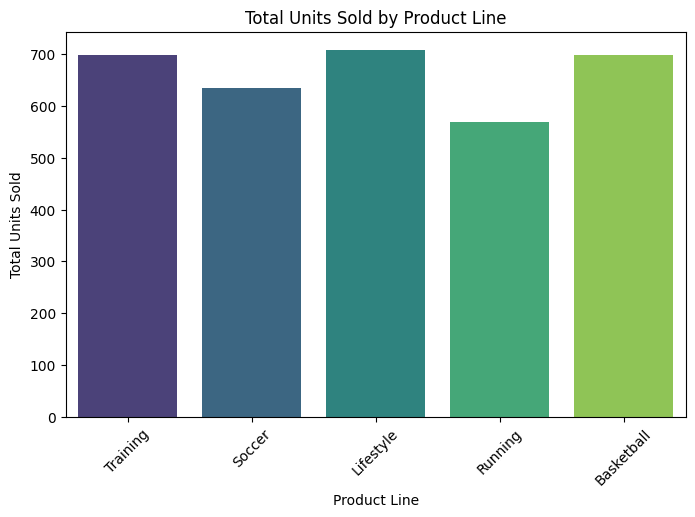

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Product_Line', y='Units_Sold', estimator=sum, ci=None, palette='viridis')
plt.title('Total Units Sold by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.show()

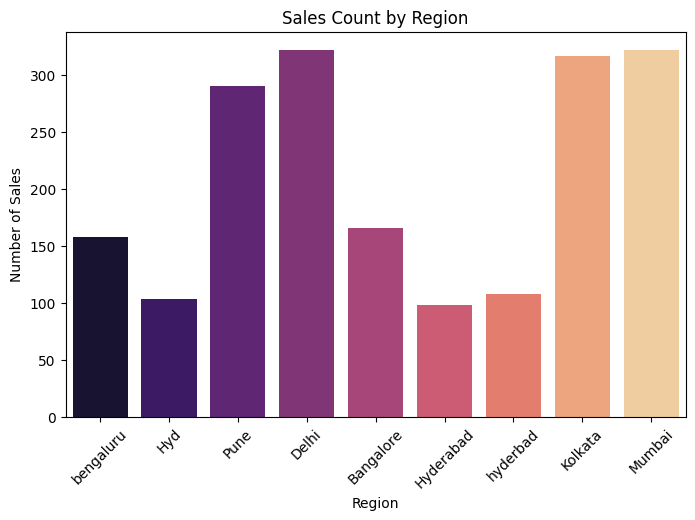

In [5]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Region', hue='Region', palette='magma', legend=False)
plt.title('Sales Count by Region')
plt.xlabel('Region')
plt.ylabel('Number of Sales')
plt.xticks(rotation=45)
plt.show()

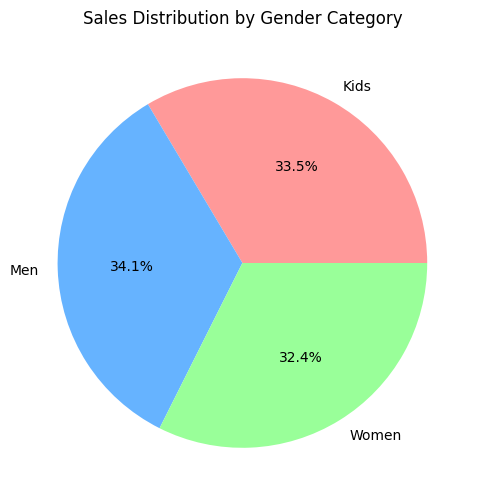

In [6]:
plt.figure(figsize=(6, 6))
df.groupby('Gender_Category')['Units_Sold'].sum().plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'])
plt.title('Sales Distribution by Gender Category')
plt.ylabel('')
plt.show()